In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('Iris1.csv')
print(f'Shape: {df.shape}')
print(f'Duplicate Rows: {df.duplicated().sum()}')
print(f'\nMissing Values:\n{df.isnull().sum()}')
print(f"\nSpecies Distribution:\n{df['Species'].value_counts()}")

Shape: (150, 6)
Duplicate Rows: 0

Missing Values:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species Distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64



=== MEAN MEASUREMENTS BY SPECIES (cm) ===
                 SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
Species                                                                  
Iris-setosa               5.01          3.42           1.46          0.24
Iris-versicolor           5.94          2.77           4.26          1.33
Iris-virginica            6.59          2.97           5.55          2.03


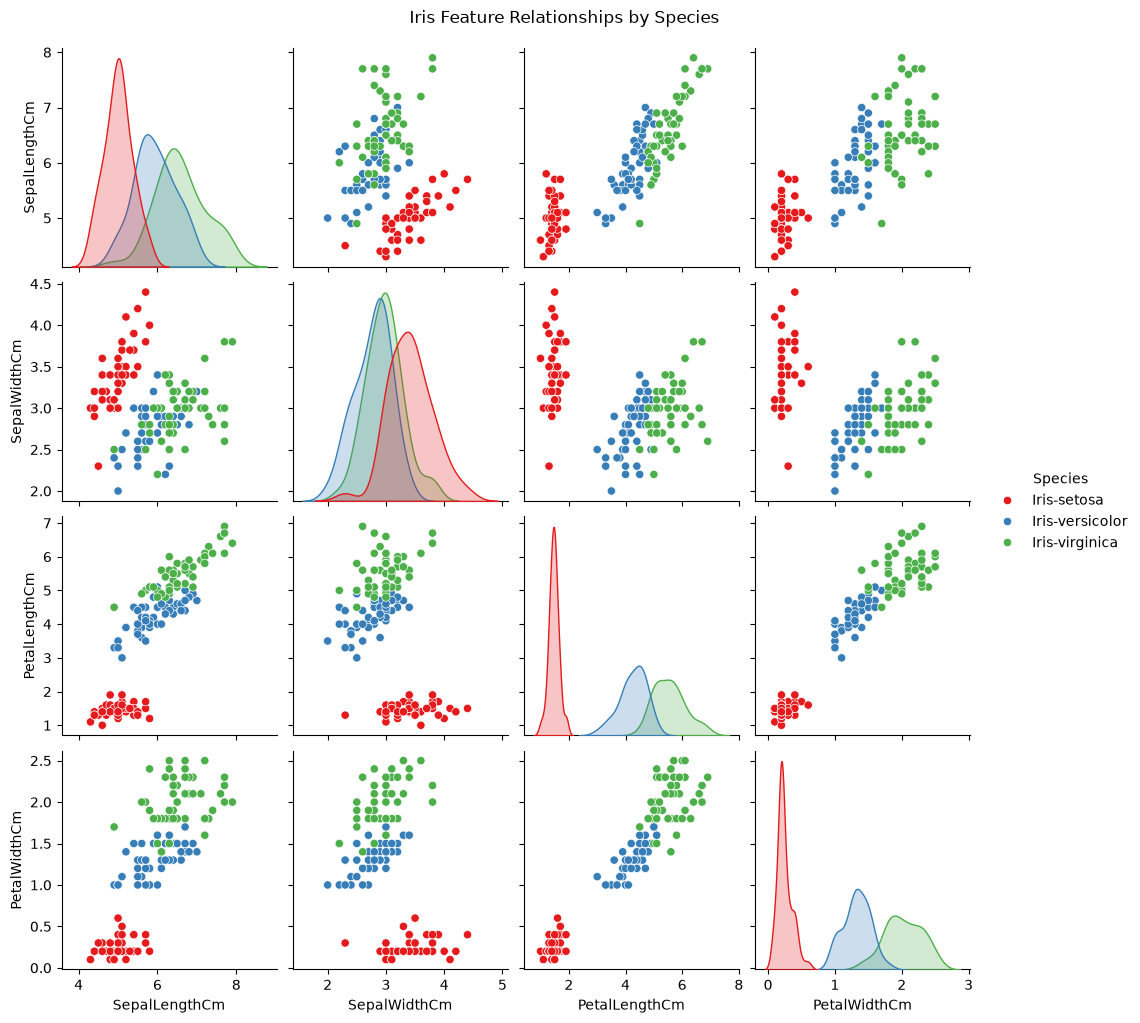

In [4]:
# 2. EXPLORATORY DATA ANALYSIS (EDA)
print('\n=== MEAN MEASUREMENTS BY SPECIES (cm) ===')
print(df.drop(columns=['Id']).groupby('Species').mean().round(2))

# Pairplot to visualize feature separation across species
sns.pairplot(
    df.drop(columns=['Id']), hue='Species', palette='Set1', diag_kind='kde'
)
plt.suptitle('Iris Feature Relationships by Species', y=1.02)
plt.show()

In [5]:
# 3. DATA PREPARATION & LEAKAGE PREVENTION
# Drop 'Id' because rows are sorted by species (keeping it causes target leakage)
X = df.drop(columns=['Id', 'Species'])
y = df['Species']

# Stratified 80/20 Train-Test Split (preserves equal 10 flowers per species in test set)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling (fit strictly on training data to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
#4. MODEL TRAINING (LINEAR VS. TREE-BASED)
# Model A: Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

# Model B: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [7]:
# 5. MODEL EVALUATION & INTERPRETATION
print('\n=== MODEL PERFORMANCE ON UNSEEN TEST SET (n=30) ===')
print(
    f'Logistic Regression Accuracy: {accuracy_score(y_test, y_pred_lr) * 100:.2f}%'
)
print(
    f'Random Forest Accuracy:       {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n'
)

print('--- Logistic Regression Classification Report ---')
print(classification_report(y_test, y_pred_lr))

# Extract Feature Importance from Random Forest
importances = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)
print('--- Feature Importance (%) ---')
print((importances * 100).round(2))


=== MODEL PERFORMANCE ON UNSEEN TEST SET (n=30) ===
Logistic Regression Accuracy: 93.33%
Random Forest Accuracy:       90.00%

--- Logistic Regression Classification Report ---
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30

--- Feature Importance (%) ---
PetalWidthCm     43.72
PetalLengthCm    43.15
SepalLengthCm    11.63
SepalWidthCm      1.50
dtype: float64


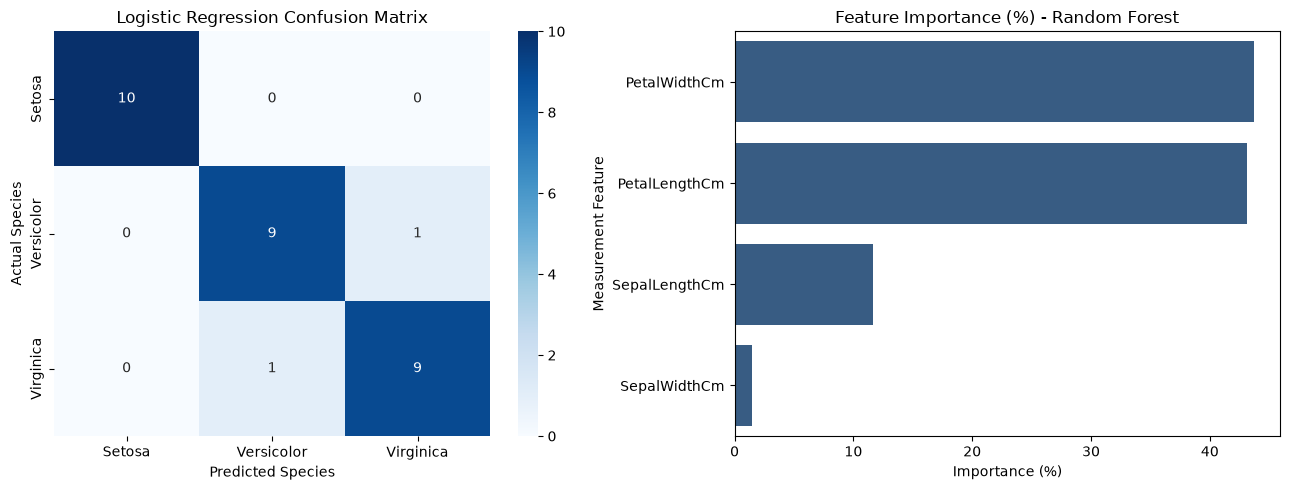

In [8]:
# 6. EVALUATION VISUALIZATIONS
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr, labels=lr_model.classes_)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Setosa', 'Versicolor', 'Virginica'],
    yticklabels=['Setosa', 'Versicolor', 'Virginica'],
    ax=axes[0],
)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Species')
axes[0].set_ylabel('Actual Species')

# Plot 2: Feature Importance Bar Chart
sns.barplot(
    x=importances.values * 100, y=importances.index, color='#2b5c8f', ax=axes[1]
)
axes[1].set_title('Feature Importance (%) - Random Forest')
axes[1].set_xlabel('Importance (%)')
axes[1].set_ylabel('Measurement Feature')

plt.tight_layout()
plt.show()